# Prof D’s Regression Sessions - Vol 4

Good Skool / Bad Skool Breaks - a logistic regression walkthrough

Adam Dennett  
Invalid Date

## Preamble

Three volumes of the Regression Sessions have all relied on the idea
that the thing we are trying to predict is a continuous number. That
number can wander up and down a straight line without ever embarrassing
us by predicting something mad!

It’s one of the core assumptions of ordinary least squares linear
regression, but today we are going to break it. Our outcome is a
**yes/no**: is this school rated below Good by Ofsted? A straight line
is the wrong tool for that job, and the first task of the practical is
to watch it fail - properly, on real data, with numbers you can point
at - before we reach for a totally different tool that fixes it.

## Practical aims

1.  Fit a linear probability model to a 0/1 outcome and find its
    impossible predictions
2.  Fit, and *read*, a binary logistic regression - including saying an
    odds ratio out loud in a sentence a non-statistician would
    understand
3.  Judge the fit with deviance, AIC and the pseudo-R²s
4.  Judge the **decisions** honestly: against a baseline, with a
    confusion matrix, and with ROC and AUC
5.  Take at least one of the two extensions further than the lecture
    went

## Before you start: the two tabs

Every code block below has an **R** tab and a **Python** tab. They are
not loose translations of each other - they do the same arithmetic on
the same rows and produce the same numbers, to four decimal places, all
the way through. If your two tabs disagree, something has gone wrong,
and that is worth chasing down.

> **Keep the whole thing reproducible**
>
> We split the data into training and test sets using the **row position
> after sorting by URN**, not a random number generator. That is
> deliberate: R’s `sample()` and Python’s random number generators will
> never agree with one another, and you would spend the afternoon
> wondering why your AUC was not mine. Sorting and taking every tenth
> school is boring, reproducible, and gives the same 2,219 training and
> 951 test schools in both languages.

# Part 0: The data

## Task 0 - Load the schools data and build the outcome

We use the same four DfE files as the lecture. Three things are
happening here that are worth noticing rather than skimming:

- **Rows with no URN are dropped.** The files carry local authority and
  national summary rows that are not schools. They also duplicate rows
  on a join, because a missing key matches another missing key.
- **Ofsted’s five published grades collapse to a binary.** `below_good`
  is 1 for *Requires improvement*, *Serious Weaknesses* and *Special
  Measures*, and 0 for *Good* and *Outstanding*.
- **We keep mainstream secondaries only**, so that we are comparing
  schools that are doing roughly the same job.
- Also note how we generate a new binary variable from OFSTEDRATING for
  schools that are below Good and the rest. This is created differently
  in R and Python.

### 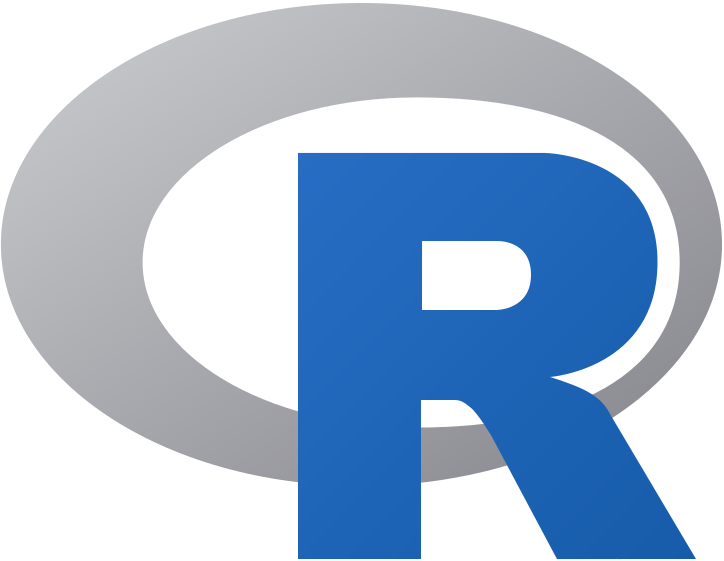

In [ ]:
library(tidyverse)
library(here)

base_path <- here("sessions", "data", "Performancetables_130242", "2022-2023")

# The DfE publishes suppressed / not-applicable values as codes, not blanks
na_all <- c("", "NA", "SUPP", "NP", "NE", "SP", "SN", "LOWCOV", "NEW", "SUPPMAT")

read_dfe <- function(f) {
  suppressWarnings(
    read_csv(file.path(base_path, f), na = na_all, show_col_types = FALSE)
  ) |>
    mutate(URN = as.character(URN)) |>
    filter(!is.na(URN))
}

ks4 <- read_dfe("england_ks4final.csv") |>
  select(URN, ATT8SCR, P8MEA, TPUP, PTFSM6CLA1A, PTPRIORHI) |>
  mutate(across(-URN, ~ parse_number(as.character(.x))))

absence <- read_dfe("england_abs.csv") |>
  distinct(URN, .keep_all = TRUE) |>
  select(URN, PERCTOT, PPERSABS10) |>
  mutate(across(-URN, ~ parse_number(as.character(.x))))

school_info <- read_dfe("england_school_information.csv") |>
  select(URN, SCHNAME, LANAME, MINORGROUP, OFSTEDRATING)

schools <- ks4 |>
  inner_join(absence, by = "URN") |>
  inner_join(school_info, by = "URN") |>
  filter(MINORGROUP %in% c("Academy", "Maintained school"),
         OFSTEDRATING %in% c("Outstanding", "Good", "Requires improvement",
                             "Serious Weaknesses", "Special Measures")) |>
  mutate(below_good = as.integer(
    OFSTEDRATING %in% c("Requires improvement", "Serious Weaknesses",
                        "Special Measures")))

# Complete cases only, sorted, so the split below is reproducible
model_data <- schools |>
  drop_na(P8MEA, PTFSM6CLA1A, PERCTOT, PPERSABS10, TPUP, PTPRIORHI) |>
  arrange(URN)

nrow(model_data)

[1] 3170

[1] 0.1498423

> **Check before you go on**
>
> You should have **3,170 schools**, and **15.0%** of them below Good.
> If you have a different number, your filters have not matched mine and
> every figure below will drift.

> **15% is the number to remember**
>
> Only 15 schools in 100 are below Good. Write that down. It is going to
> come back and ruin our afternoon at Task 10, in the most instructive
> way possible.

# Part 1: Watching a straight line fail

## Task 1 - Fit the linear probability model

Before we do anything clever, do the obvious wrong thing. `below_good`
is a column of 0s and 1s, and nothing stops you putting it on the left
of an `lm()`. So put it there, regress it on Progress 8, and look at
what comes back out.

### 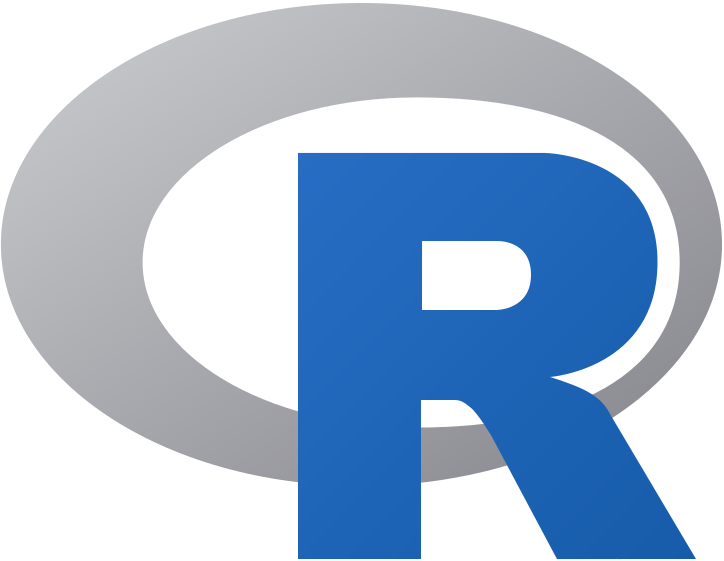

In [ ]:
lpm <- lm(below_good ~ P8MEA, data = model_data)
fitted_lpm <- fitted(lpm)

range(fitted_lpm)

[1] -0.5043234  1.0510934

[1] 457

[1] 1


Call:
lm(formula = below_good ~ P8MEA, data = model_data)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.05109 -0.19520 -0.10193  0.03523  1.13124 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.145824   0.005812   25.09   <2e-16 ***
P8MEA       -0.274324   0.011145  -24.61   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.3271 on 3168 degrees of freedom
Multiple R-squared:  0.1606,    Adjusted R-squared:  0.1603 
F-statistic: 605.9 on 1 and 3168 DF,  p-value: < 2.2e-16

The model’s lowest fitted value is about **-0.50**. It is telling us
that a school with very strong Progress 8 has a **minus fifty per cent
chance** of being rated below Good.

**457 schools** are given a negative probability. One is given a
probability above 1.

> **Question**
>
> A probability of -0.5 is not merely an unlikely event, or a very small
> chance. What *is* it? And can you fix this by just rounding the
> negative predictions up to zero? Write down one reason why that patch
> would be dishonest before you read on.

## Task 2 - See it

Numbers are easy to shrug at. Plot it.

### 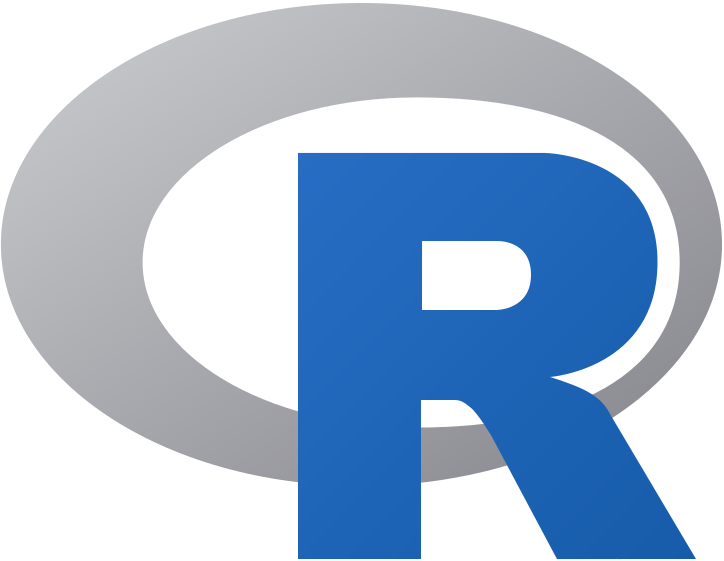

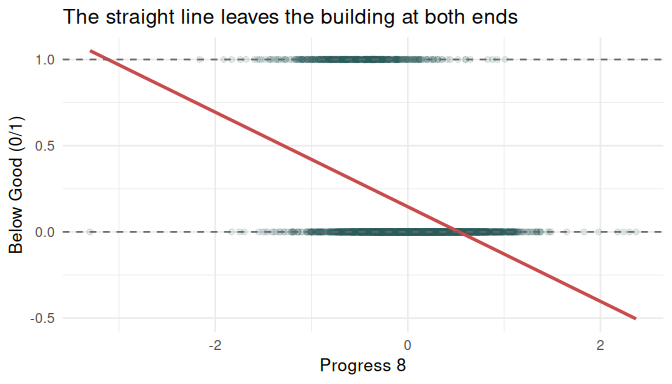

In [ ]:
ggplot(model_data, aes(x = P8MEA, y = below_good)) +
  geom_point(alpha = 0.12, colour = "#2E6260") +
  geom_smooth(method = "lm", se = FALSE, colour = "#C94C4C") +
  geom_hline(yintercept = c(0, 1), linetype = "dashed", colour = "grey40") +
  labs(x = "Progress 8", y = "Below Good (0/1)",
       title = "The straight line leaves the building at both ends") +
  theme_minimal(base_size = 13)

The dashed lines at 0 and 1 are the only values the outcome can actually
take. The red line crosses both of them and keeps going, because that is
what straight lines do. **Nothing in `lm()` knows that probabilities
stop.**

# Part 2: Your first logistic regression

## Task 3 - Fit it

The fix is to stop modelling the probability directly, and model the
**log-odds** of it instead - a quantity that is perfectly happy running
from minus infinity to plus infinity. That is the *link function*, and
in R and Python it is one argument.

### 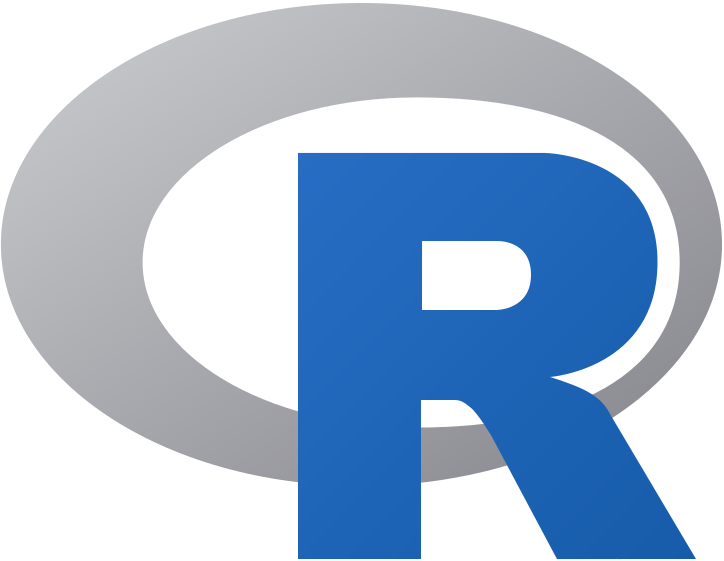

In [ ]:
logit1 <- glm(below_good ~ P8MEA, data = model_data, family = binomial)

summary(logit1)


Call:
glm(formula = below_good ~ P8MEA, family = binomial, data = model_data)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept) -2.32354    0.07386  -31.46   <2e-16 ***
P8MEA       -2.69867    0.13673  -19.74   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 2678.2  on 3169  degrees of freedom
Residual deviance: 2117.2  on 3168  degrees of freedom
AIC: 2121.2

Number of Fisher Scoring iterations: 6

Both languages give you an intercept of **-2.3235** and a Progress 8
coefficient of **-2.6987**. Check that yours match before going on.

> **What changed, and what didn’t**
>
> `glm(..., family = binomial)` instead of `lm(...)`. That is the whole
> difference in the code. Everything you learned about reading a
> `summary()` table - estimates, standard errors, p-values, which
> predictors earn their place - still applies. What has changed is
> **what the estimates mean**, and that is the next two tasks.

## Task 4 - The recipe for reading a coefficient

Those coefficients are on the log-odds scale, and nobody thinks in
log-odds. The recipe is three steps, and you will use it for the rest of
your life:

> **The recipe**
>
> 1.  **Exponentiate the coefficient.** `exp(coef)` turns a log-odds
>     difference into an **odds ratio**.
> 2.  **The odds ratio is the multiplier for a one-unit increase** in
>     that predictor.
> 3.  **Say it out loud.** Above 1 means the odds go up; below 1 means
>     they go down.

### 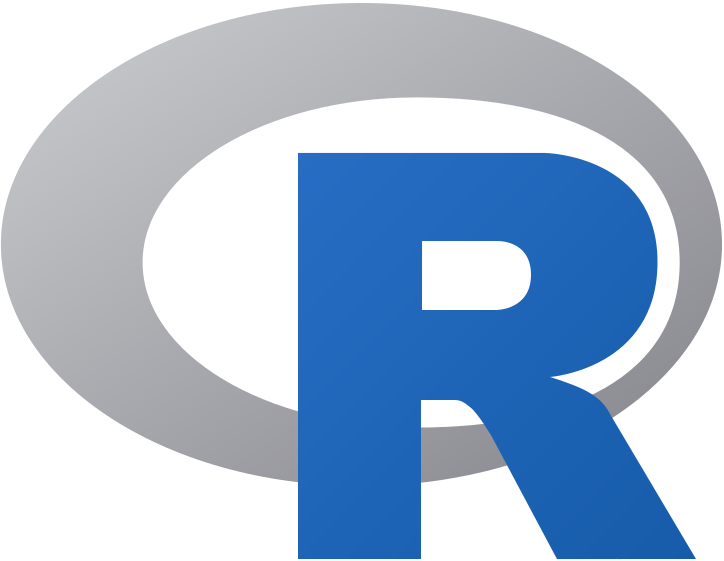

In [ ]:
exp(coef(logit1))

(Intercept)       P8MEA 
 0.09792662  0.06729478 

You should get **0.0979** for the intercept and **0.0673** for Progress
8.

Step 3 is the one that is actually hard, and the one the assessment will
ask you for. Here is the Progress 8 one written out:

> *Every one-point increase in Progress 8 multiplies a school’s odds of
> being rated below Good by **0.067** - that is, it cuts them to about a
> fifteenth.*

> **Question**
>
> Write the same sentence for the **intercept**. Two warnings. First,
> Progress 8 is already centred so that 0 is the national average, which
> makes the intercept meaningful here - it is the odds for an average
> school. Second, check it against the data: of the 283 schools within
> 0.05 of a Progress 8 of zero, what fraction really are below Good? You
> should find about **6%**, where the model puts them at **8.9%**. The
> model is not obliged to match the local average - it is fitting one
> smooth curve across the whole range, and this is where you see the
> price of that. Is it a price worth paying?

## Task 5 - And back to a probability

Odds are not probabilities, and your reader will want a probability.
Going back is one line, and you never have to do it by hand.

### 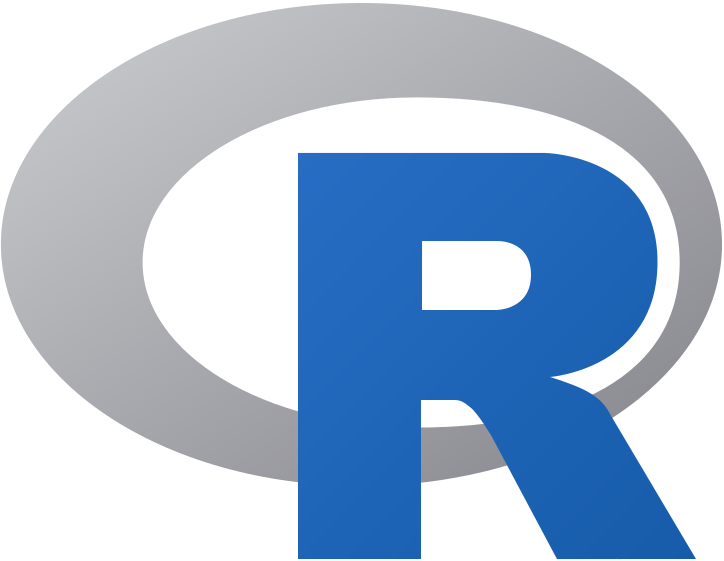

In [ ]:
new_schools <- data.frame(P8MEA = c(-1, -0.5, 0, 0.5, 1))
new_schools$prob <- predict(logit1, newdata = new_schools, type = "response")
new_schools

  P8MEA        prob
1  -1.0 0.592699378
2  -0.5 0.274044036
3   0.0 0.089192317
4   0.5 0.024774032
5   1.0 0.006546807

> **Question**
>
> `type = "response"` in R, and plain `.predict()` in Python, both give
> you a probability. Look at the five numbers. Are they equally spaced?
> The Progress 8 values are. Why aren’t the probabilities - and is that
> a bug or the entire point of what we did in Task 3?

# Part 3: More than one predictor

## Task 6 - The full model, and the split

Two things happen at once here, and it is worth being clear about why.

First, we add predictors. Second - and this is new - we **stop fitting
to all the data**. From here on the model is fitted on 70% of schools
and judged on the 30% it has never seen. Everything in Part 5 depends on
that separation, so we do it before we fit rather than bolting it on
afterwards.

> **Why bother — remember the wiggly red line**
>
> The lecture showed two models fitted to fifteen points: a sensible
> curve, and one forced through every single point. The second had an
> average error of **0.00** on the data it was fitted to, and was the
> **worse** of the two on fifteen points it had never seen.
>
> That is overfitting, and it is why a model’s performance on its own
> training data is not evidence. You can always improve that number by
> adding terms. The only honest test is data the model has never seen -
> which is what the next two lines create.

### 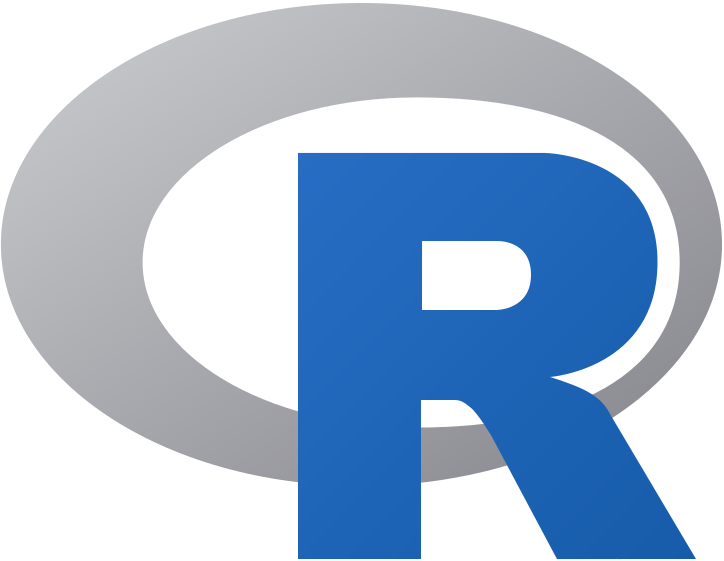

In [ ]:
# Deterministic split on sorted row position - identical in R and Python.
# Note the - 1: R counts rows from 1 and Python from 0, and without it the
# two languages would quietly select different schools.
idx   <- seq_len(nrow(model_data)) - 1
test  <- model_data[idx %% 10 <  3, ]
train <- model_data[idx %% 10 >= 3, ]

c(train = nrow(train), test = nrow(test))

train  test 
 2219   951 


Call:
glm(formula = below_good ~ P8MEA + PTFSM6CLA1A + PERCTOT + PPERSABS10 + 
    log(TPUP) + PTPRIORHI, family = binomial, data = train)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) -4.737563   0.988917  -4.791 1.66e-06 ***
P8MEA       -2.265192   0.217525 -10.413  < 2e-16 ***
PTFSM6CLA1A -0.018562   0.006179  -3.004  0.00266 ** 
PERCTOT      0.200477   0.077634   2.582  0.00981 ** 
PPERSABS10   0.003247   0.024202   0.134  0.89327    
log(TPUP)    0.228647   0.173850   1.315  0.18844    
PTPRIORHI   -0.010208   0.009811  -1.040  0.29812    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1934.5  on 2218  degrees of freedom
Residual deviance: 1467.2  on 2212  degrees of freedom
AIC: 1481.2

Number of Fisher Scoring iterations: 6

You should have **2,219 training** and **951 test** schools, and an
intercept of **-4.7376**.

> **Your numbers will not match the lecture’s — and that is correct**
>
> The lecture split the schools with `set.seed(42)` and `sample()`. We
> split on sorted row position instead, for the reason given at the top:
> R’s and Python’s random number generators will never agree with each
> other.
>
> Both splits take 70/30 of the same 3,170 schools, so **both give 2,219
> and 951**. But they are a *different* 951 schools — so every test-set
> figure from here on differs a little from the lecture’s:
>
> |                         | Lecture | Here      |
> |-------------------------|---------|-----------|
> | Test-set accuracy       | 86.2%   | **86.9%** |
> | Majority-class baseline | 85.3%   | **86.9%** |
> | AUC                     | 0.818   | **0.812** |
>
> Do not go hunting for a bug. The conclusion is the same in both, and
> here it is even clearer: in the lecture the model beat the baseline by
> 0.9 points, and on this split it does not beat it **at all**.

## Task 7 - Say all six out loud

Same recipe as Task 4, applied six times.

### 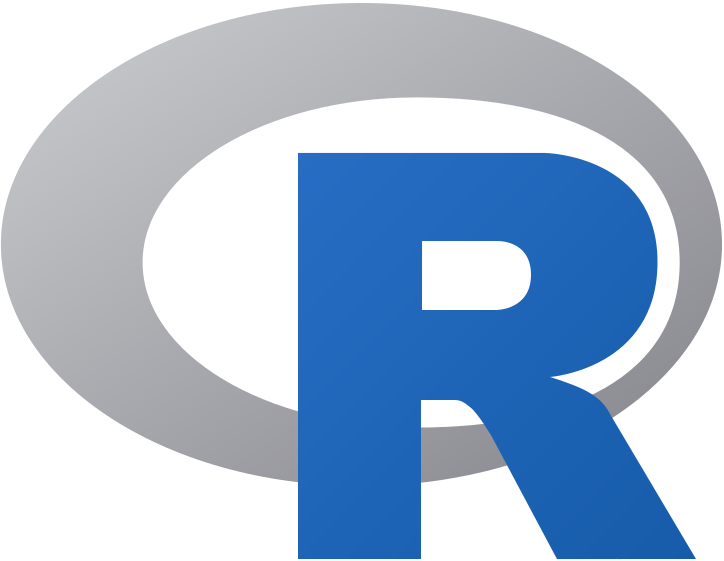

In [ ]:
round(exp(coef(logit_full)), 4)

(Intercept)       P8MEA PTFSM6CLA1A     PERCTOT  PPERSABS10   log(TPUP) 
     0.0088      0.1038      0.9816      1.2220      1.0033      1.2569 
  PTPRIORHI 
     0.9898 

> **Question - this is the exercise, not the code**
>
> Write one plain-English sentence per predictor. Then answer two harder
> questions:
>
> 1.  `PERCTOT` (overall absence) has an odds ratio above 1, and
>     `PTFSM6CLA1A` (free school meals) has one just below. Does that
>     mean absence matters and poverty does not? What else changed when
>     you moved from one predictor to six?
> 2.  The intercept is now the odds for a school with Progress 8 of
>     zero, **zero free school meals, zero absence, zero
>     prior-high-attainers and a cohort of one pupil** - because
>     `log(TPUP)` is 0 when `TPUP` is 1. How many such schools exist?
>     What does that tell you about quoting the intercept in a write-up?

## Task 8 - Centre the predictors, and get an intercept worth quoting

Task 7 left you with a useless intercept: the odds for a school with a
cohort of one pupil, no absence and no disadvantaged pupils. No such
school exists.

There is a standard fix. **Subtract each predictor’s mean from itself**,
so that zero stops meaning *none* and starts meaning *average*. Progress
8 already arrives this way - that is why it behaved sensibly in Task 3.

### 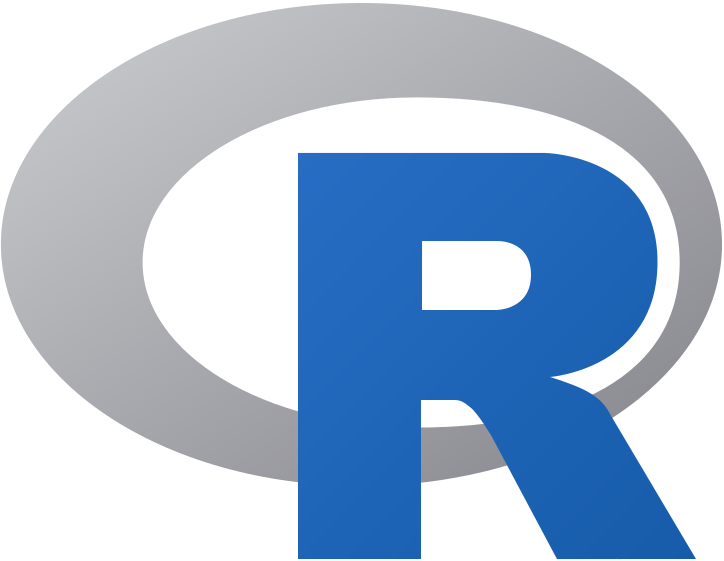

In [ ]:
train_c <- train |>
  mutate(log_TPUP = log(TPUP),
         across(c(P8MEA, PTFSM6CLA1A, PERCTOT, PPERSABS10, log_TPUP, PTPRIORHI),
                ~ .x - mean(.x), .names = "c_{.col}"))

logit_centred <- glm(below_good ~ c_P8MEA + c_PTFSM6CLA1A + c_PERCTOT +
                       c_PPERSABS10 + c_log_TPUP + c_PTPRIORHI,
                     data = train_c, family = binomial)

# the intercept, three ways
c(log_odds = coef(logit_centred)[[1]],
  odds     = exp(coef(logit_centred)[[1]]),
  prob     = plogis(coef(logit_centred)[[1]]))

   log_odds        odds        prob 
-2.31740588  0.09852885  0.08969164 

> **Compare the two intercepts**
>
> |                         | Intercept | $e^{\beta_0}$ (odds) | as a probability |
> |-------------------------|-----------|----------------------|------------------|
> | Task 6 model, uncentred | −4.7376   | 0.0088               | **0.9%**         |
> | Centred                 | −2.3174   | 0.0985               | **9.0%**         |
>
> The first describes a school that does not exist. The second describes
> a school at the average of every predictor - and **that** is a
> sentence you can put in a report.

> **Questions**
>
> 1.  **Compare the other six coefficients with the ones from Task 7.**
>     They should be *identical* - and so should the deviance, the AIC
>     and every pseudo-R². Check that they are. If centring changes none
>     of those, what exactly *has* it changed, and why was it worth
>     doing?
> 2.  Write the sentence. “A school at the national average on every one
>     of these measures has a \_\_\_ chance of being rated below Good.”
> 3.  **The awkward one.** 15.8% of the training schools really are
>     below Good, but the centred intercept says an *average* school has
>     a 9.0% chance. Those are not the same number and neither is wrong.
>     Why not? *(Hint: the model is linear in log-odds, not in
>     probability - so the probability at the average school is not the
>     average of the probabilities. You met this in Week 1 as the
>     difference between the mean of the logs and the log of the mean.)*
> 4.  Centring is not the only option. What would you subtract instead
>     if you wanted the intercept to describe a *specific, real*
>     school - say, a median-sized school in your own local authority?

# Part 4: Does the model fit?

## Task 9 - Deviance, AIC and the pseudo-R-squareds

There is no R-squared here, because there are no residuals in the sense
OLS means. What we have instead is a set of numbers built on the
**likelihood** - how surprised the model is by the data it saw.

Every one of these is already sitting in the output you printed at Task
6. The point of this task is to find them there, not to compute them
afresh.

### 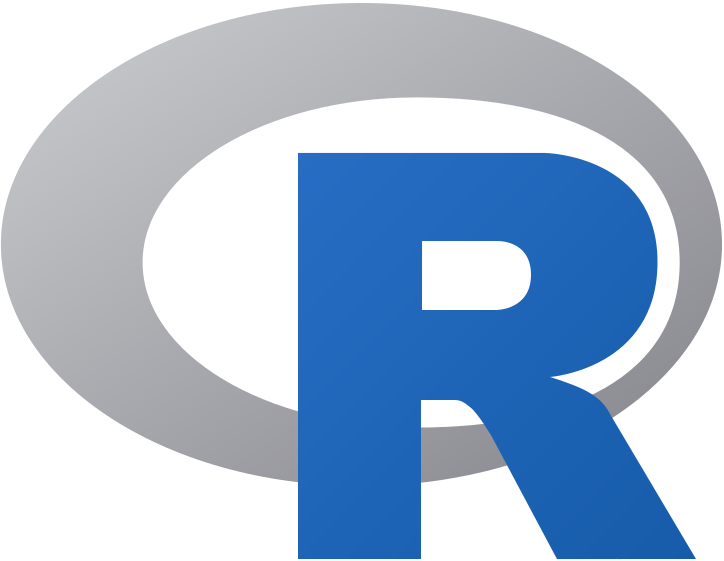

In [ ]:
logLik(logit_full)

'log Lik.' -733.5766 (df=7)

[1] 1934.454

[1] 1467.153

[1] 1481.153

Cox & Snell's R2 
       0.1898946 

Nagelkerke's R2 
      0.3263978 

> **Python trap — `.prsquared` is not the number you just computed**
>
> `smf.glm()` has no `.prsquared` attribute. `smf.logit()` **does**, and
> it is very tempting to reach for it instead of writing those two lines
> out.
>
> It is **McFadden’s** pseudo-R², which is a different measure built a
> different way. Fit this model both ways and compare:
>
> ``` python
> lg = smf.logit("below_good ~ P8MEA + PTFSM6CLA1A + PERCTOT + PPERSABS10 "
>                "+ np.log(TPUP) + PTPRIORHI", data=train).fit(disp=0)
> print(lg.prsquared)
> ```
>
> You should get **0.2416**, against the **0.3264** Nagelkerke you
> computed above. Same data, same fit, two numbers with the same
> nickname. Whichever you report, **name it**.
>
> R users are not immune: `performance::r2_mcfadden()` sits right next
> to `r2_nagelkerke()` and will give you the same 0.2416.

> **How to read them**
>
> - **Null deviance vs residual deviance.** The first is how badly an
>   intercept-only model does; the second is how badly ours does. The
>   drop between them is what the predictors bought you.
> - **AIC** is the log-likelihood with a fine for each extra parameter.
>   It is only meaningful **compared with another model on the same
>   data** - an AIC on its own means nothing at all.
> - **Cox & Snell** cannot reach 1, even for a perfect model.
>   **Nagelkerke** rescales it so that it can. Neither one is “the
>   proportion of variance explained”, whatever your software calls it.

> **Question**
>
> Drop `PTPRIORHI` and refit. Does AIC go up or down? Now drop `P8MEA`
> instead. Which of the two was carrying the model - and does the answer
> surprise you, given the p-values?

# Part 5: Does it make good decisions?

> **This part is not just about logistic regression**
>
> Holding data back, comparing against a baseline, and separating *fit*
> from *prediction* apply to **every** model you will ever build,
> including the OLS and multilevel models of the past three weeks. What
> is specific to today is only the **scoreboard** - accuracy, confusion
> matrices and AUC need a categorical outcome to be defined at all.

## Task 10 - Predict, and compare with doing nothing

The model does not hand back a yes or a no. For each school it hands
back a **probability**, so before counting anything, watch what the 0.5
cut-off does to four individual schools.

### 10a - Four schools, one at a time

### 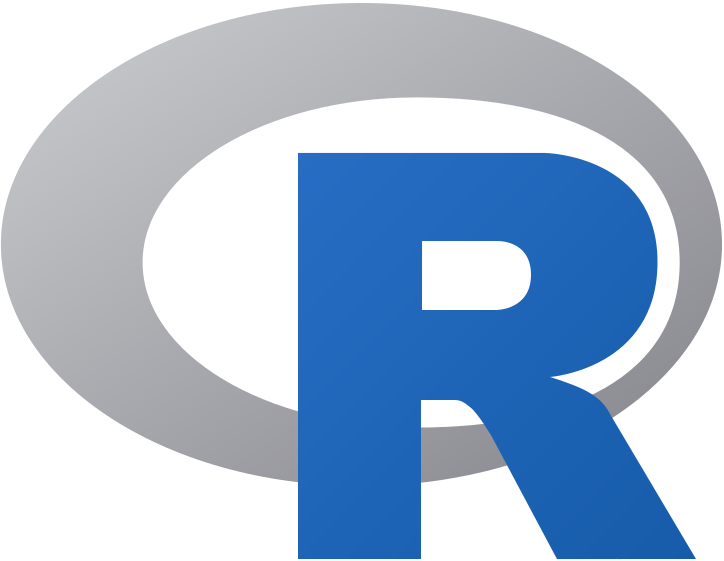

In [ ]:
p_below <- predict(logit_full, newdata = test, type = "response")

flag <- p_below > 0.5
act  <- test$below_good == 1

# one real school nearest each of four illustrative probabilities
pick <- function(sel, target) {
  i <- which(sel); i[which.min(abs(p_below[i] - target))]
}
idx <- c(pick(!flag & !act, 0.03), pick(flag &  act, 0.70),
         pick(!flag &  act, 0.30), pick(flag & !act, 0.60))

data.frame(
  school      = c("A", "B", "C", "D"),
  probability = round(p_below[idx], 2),
  above_0.5   = ifelse(p_below[idx] > 0.5, "yes", "no"),
  predicted   = ifelse(p_below[idx] > 0.5, "Below Good", "Good or better"),
  actual      = ifelse(act[idx], "Below Good", "Good or better"),
  right       = ifelse((p_below[idx] > 0.5) == act[idx], "yes", "no"),
  row.names   = NULL
)

  school probability above_0.5      predicted         actual right
1      A        0.03        no Good or better Good or better   yes
2      B        0.72       yes     Below Good     Below Good   yes
3      C        0.30        no Good or better     Below Good    no
4      D        0.60       yes     Below Good Good or better    no

> **What just happened**
>
> **C** was missed and **D** was a false alarm. Each school is judged on
> **its own** probability - the cut-off simply sorts them either side of
> the line, one school at a time.
>
> So **0.5 is not “half the time”**. Applied to all 951 test schools it
> flags 48 of them, not 476.

### 10b - Now count them all

Here is the whole trap in one step. Count how often you were right, and
then count how often you would have been right by **not building a model
at all** - by simply saying “not below Good” to every school.

### 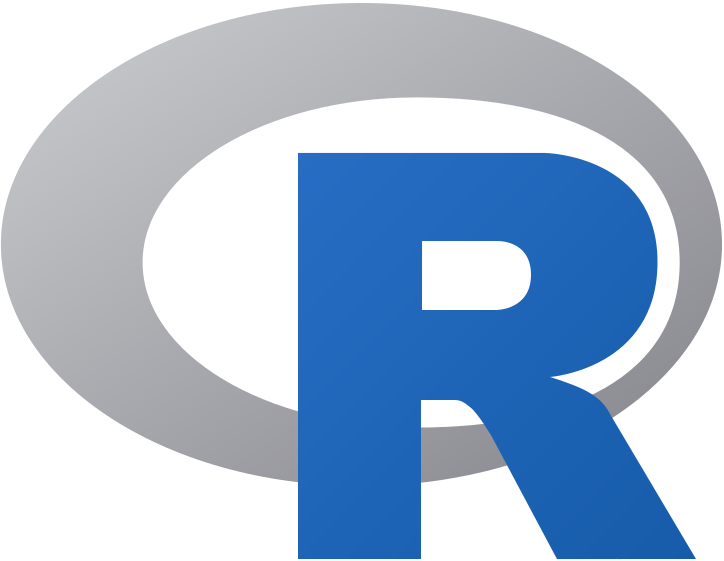

In [ ]:
p_below  <- predict(logit_full, newdata = test, type = "response")

accuracy <- mean((p_below > 0.5) == test$below_good)
baseline <- max(mean(test$below_good), 1 - mean(test$below_good))

c(accuracy = round(accuracy, 4), baseline = round(baseline, 4))

accuracy baseline 
  0.8686   0.8686 

> **Stop here and look at those two numbers**
>
> They are **the same**: 0.8686 and 0.8686. Six predictors, a proper
> model, a clean train/test split - and it classifies schools **exactly
> as well as a rule that ignores the data entirely**.
>
> This is not a mistake in your code. It is what the 15% was always
> going to do to us, and it is the most useful result in this practical.

### 10c - That baseline is a model you have already fitted

We worked the baseline out arithmetically - *what share would I get
right by always guessing the commoner answer?* But it is also a
**model**: an intercept and nothing else. R and `statsmodels` will fit
it for you.

### 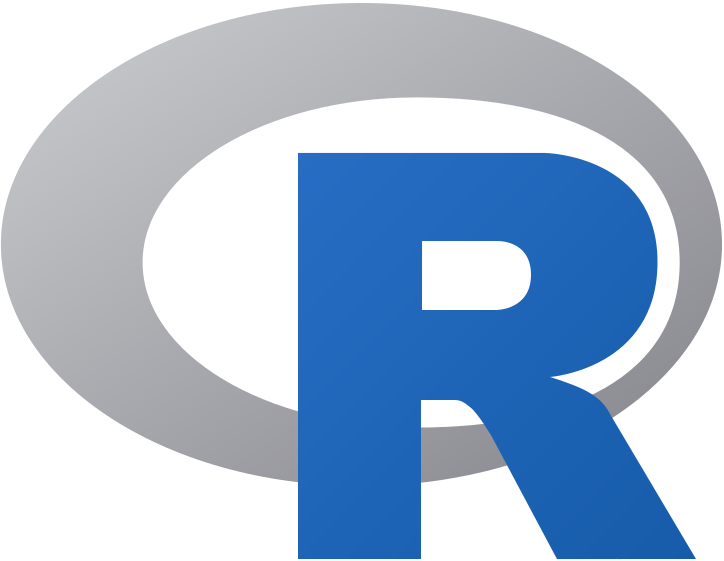

In [ ]:
null_mod <- glm(below_good ~ 1, data = train, family = binomial)
p_null   <- predict(null_mod, newdata = test, type = "response")

c(distinct_predictions = length(unique(round(p_null, 10))),
  it_predicts          = round(unique(p_null)[[1]], 4),
  its_accuracy         = round(mean((p_null > 0.5) == test$below_good), 4),
  our_baseline         = round(baseline, 4))

distinct_predictions          it_predicts         its_accuracy 
              1.0000               0.1577               0.8686 
        our_baseline 
              0.8686 

> **Why they are the same number**
>
> The null model makes **one** distinct prediction - 0.1577, the share
> of training schools below Good - for every school in the test set.
> That is below 0.5, so thresholding sends *every* school to “Good or
> better”, which is exactly the always-say-no rule. Hence the identical
> accuracy.
>
> Now compare `null_mod$deviance` with the `null_deviance` you printed
> back in Task 9. **They are the same number**, because that is what
> null deviance *is*: the deviance of this model. R has been fitting it
> for you every time you call `glm()` - you have just never looked at
> it.

> **Question**
>
> Would the two still agree if below-Good schools were the
> **majority** - say 60% of them? Work out what the null model would
> predict, what thresholding at 0.5 would then do, and what the
> majority-class baseline would be.

## Task 11 - The confusion matrix shows you why

Accuracy is one number squashed out of four, and the four are more
honest.

### 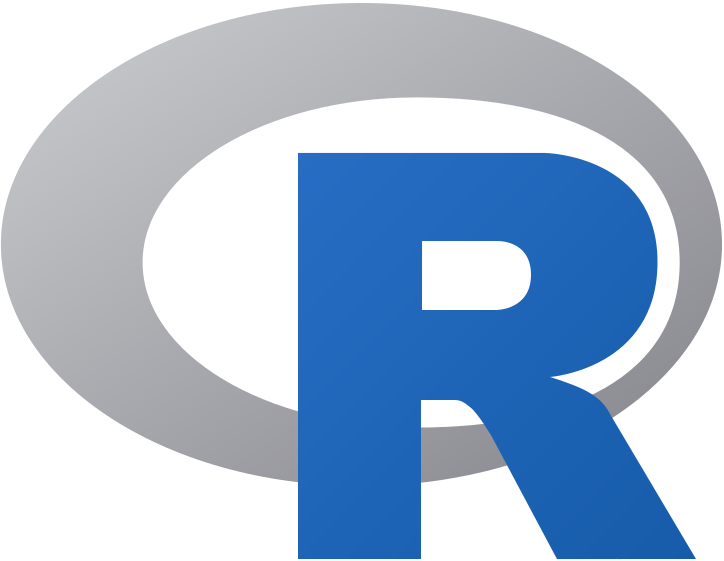

In [ ]:
table(Actual    = ifelse(test$below_good == 1, "Below Good", "Good or better"),
      Predicted = ifelse(p_below > 0.5,        "Below Good", "Good or better"))

                Predicted
Actual           Below Good Good or better
  Below Good             24            101
  Good or better         24            802

Of the 125 schools that really are below Good, the model flags **24**
and misses **101**. It also raises **24** false alarms. The gains and
the losses cancel exactly, which is why accuracy came out identical to
the baseline.

> **Question**
>
> A school improvement team has to decide where to send inspectors.
> Which of the four cells in that table costs them most? Does accuracy
> weight it that way?

## Task 12 - ROC and AUC: judge the ranking instead

Everything above hung on the cut-off of **0.5**, and nothing made 0.5
right. So ask a question that does not depend on it at all: does the
model put schools in the right **order**?

**ROC** stands for *Receiver Operating Characteristic*, a name inherited
from WWII radar operators and one that tells you nothing useful. **AUC**
is the *Area Under the Curve*.

### 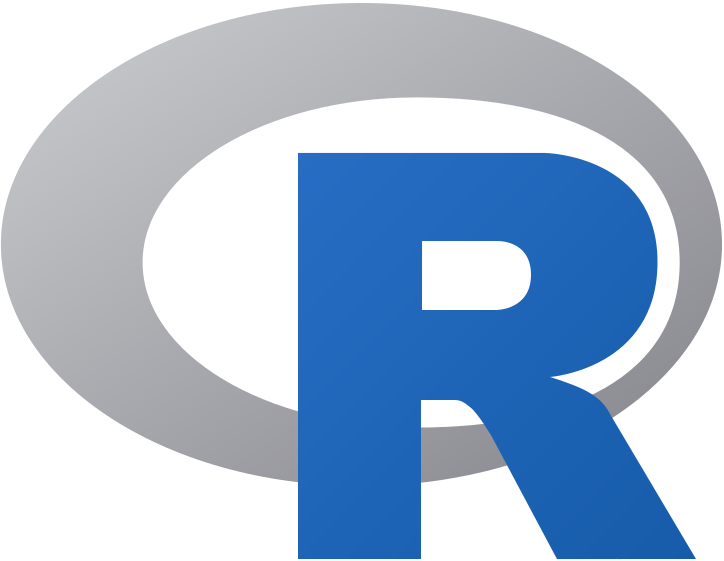

[1] 0.8118063

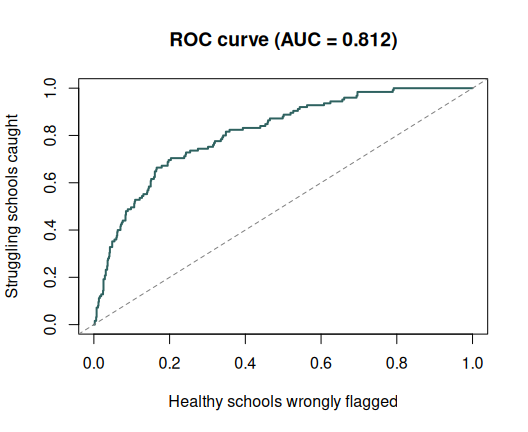

In [ ]:
roc <- performance::performance_roc(logit_full, new_data = test)
auc <- bayestestR::area_under_curve(roc$Specificity, roc$Sensitivity)
auc

**AUC comes out at 0.812.** Read it like this:

> *Pick one school that really is below Good and one that really is not.
> The model gives the struggling one the higher **predicted probability
> of being below Good** 81% of the time.*

That “predicted probability” is the model’s own output - the 0-to-1
number you called `p_below` - and not Progress 8 or any other predictor.

> **Both things are true at once**
>
> The model classifies no better than doing nothing, **and** it ranks
> schools well. There is no contradiction. We were reading a good
> ranking at a cut-off that threw the ranking away.

## Task 13 - Now choose a cut-off

Only now that you know the model ranks sensibly is the cut-off a
sensible question - and it is a **policy** question, not a statistical
one.

### 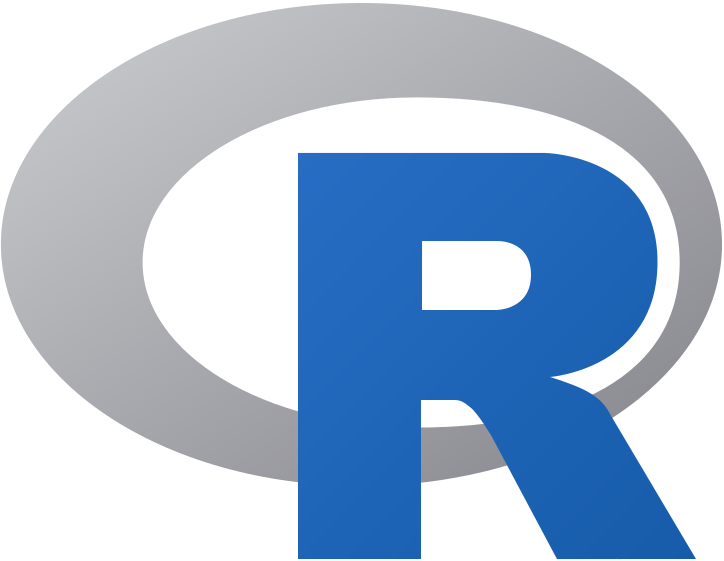

In [ ]:
thresholds <- c(0.5, 0.3, 0.2, 0.1)

data.frame(
  cut_off      = thresholds,
  caught       = sapply(thresholds, function(t) sum(p_below >  t & test$below_good == 1)),
  missed       = sapply(thresholds, function(t) sum(p_below <= t & test$below_good == 1)),
  false_alarms = sapply(thresholds, function(t) sum(p_below >  t & test$below_good == 0))
)

  cut_off caught missed false_alarms
1     0.5     24    101           24
2     0.3     60     65           73
3     0.2     83     42          147
4     0.1    104     21          328

> **Question - and it is the one that matters**
>
> Pick a cut-off and **defend it in two sentences**, naming who bears
> the cost of the misses and who bears the cost of the false alarms.
> There is no correct answer here, and that is the point: AUC told you
> the curve was worth picking from, but it cannot tell you where on it
> to sit.

# Part 6: Extensions

Two routes out of here. **Pick one** - they are both a solid hour - and
come back for the other if you have time. Extension A connects today to
last week; Extension B connects today to the rest of the GLM family.

## Extension A - Take ROC back to the multilevel model

Last week you fitted a linear mixed effects model with local authority
as a grouping variable. The obvious question is whether you can put a
ROC curve on it.

> **Read this before you try - the honest answer is ‘not directly’**
>
> **You cannot run a ROC curve on last week’s model as it stands.** ROC
> and AUC need a **binary** outcome: the curve is built by counting how
> many of the 1s you caught against how many of the 0s you wrongly
> flagged, and if the outcome is a continuous Attainment 8 score there
> are no 1s and 0s to count.
>
> This is not a technicality to work around. It is the same point as the
> callout at the top of Part 5: holding data back and comparing against
> a baseline transfer to any model, but **the scoreboard does not**.
>
> So the interesting version of this extension is not “ROC the old
> model”. It is: **keep the grouping structure, change the outcome to a
> binary one, and you get a model that is both of the last two weeks at
> once** - a generalised linear *mixed* model.

### A1 - Fit a mixed-effects logistic regression

A random intercept for local authority, on top of the logistic
regression you already have. In R this is `glmer()` - `lmer()` with a
`family` argument, exactly the way `glm()` was `lm()` with a `family`
argument.

### 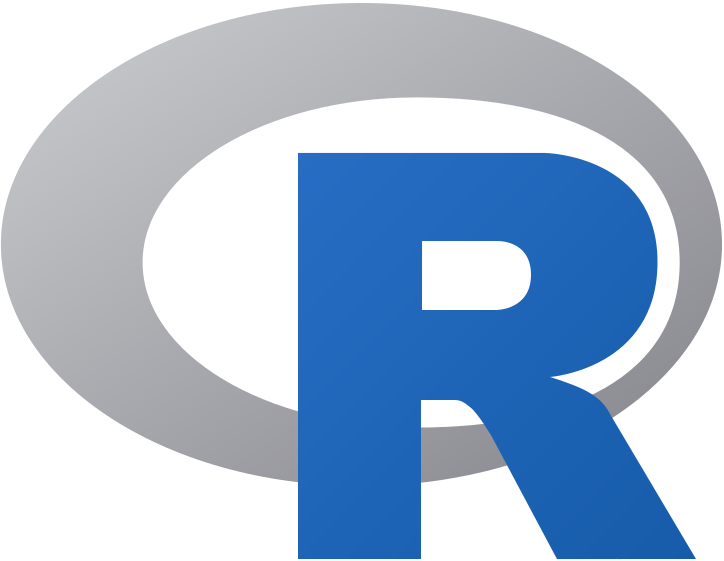

In [ ]:
library(lme4)

glmm <- glmer(below_good ~ P8MEA + PTFSM6CLA1A + PERCTOT + (1 | LANAME),
              data = train, family = binomial)

summary(glmm)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: binomial  ( logit )
Formula: below_good ~ P8MEA + PTFSM6CLA1A + PERCTOT + (1 | LANAME)
   Data: train

      AIC       BIC    logLik -2*log(L)  df.resid 
   1473.7    1502.2    -731.8    1463.7      2214 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-8.1764 -0.3804 -0.2285 -0.1087 12.4463 

Random effects:
 Groups Name        Variance Std.Dev.
 LANAME (Intercept) 0.1881   0.4337  
Number of obs: 2219, groups:  LANAME, 151

Fixed effects:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept) -4.05177    0.36170 -11.202  < 2e-16 ***
P8MEA       -2.27607    0.22118 -10.291  < 2e-16 ***
PTFSM6CLA1A -0.01819    0.00640  -2.842  0.00448 ** 
PERCTOT      0.23100    0.03827   6.036 1.58e-09 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Correlation of Fixed Effects:
            (Intr) P8MEA  PTFSM6
P8MEA       -0.402              
PTFSM6CLA1

 Groups Name        Std.Dev.
 LANAME (Intercept) 0.43372 

> **A real difference between the two languages**
>
> This is the one place in the practical where the tabs do **not** give
> you the same numbers, and you should know why.
>
> `glmer()` fits by maximum likelihood. statsmodels’
> `BinomialBayesMixedGLM` fits by **variational Bayes** - a different
> estimator of a differently specified model - so the coefficients land
> close but not identical, and the summary reports posterior means
> rather than estimates and standard errors. The local authority
> standard deviation comes out at about **0.43** from `glmer()` and
> **0.45** from statsmodels - close enough that the conclusion is the
> same either way, which is the point.
>
> Python’s mixed-model support is genuinely thinner than R’s - and you
> will feel it in A2, where there is no `predict()` that takes new data
> *and* the random effects, so we rebuild the linear predictor by hand.
> If you need mixed models seriously in Python, `pymer4` (which calls
> lme4 underneath) and `bambi` are the usual answers.

### A2 - Did the grouping actually help the ranking?

Here is where today’s scoreboard earns its keep. Fit the same model
**without** the random intercept, predict both on the held-out schools,
and compare AUC.

### 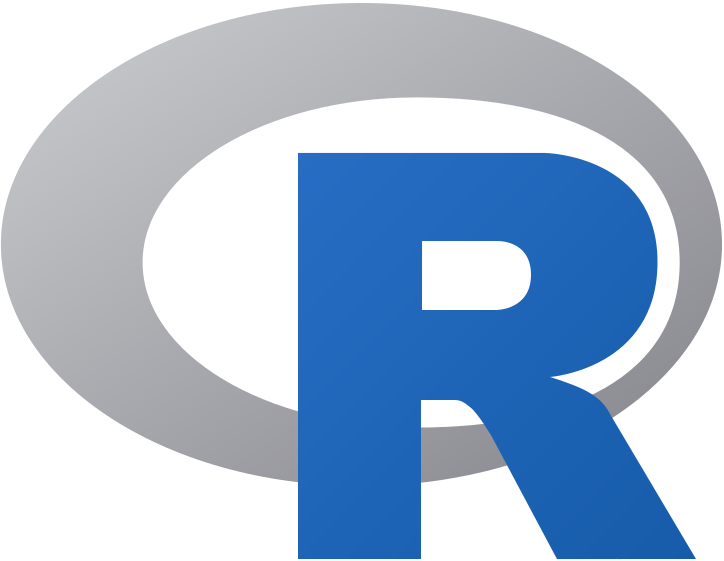

In [ ]:
flat <- glm(below_good ~ P8MEA + PTFSM6CLA1A + PERCTOT,
            data = train, family = binomial)

auc_of <- function(scores, actual) {
  r  <- rank(scores)
  n1 <- sum(actual == 1); n0 <- sum(actual == 0)
  (sum(r[actual == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0)
}

p_glmm <- predict(glmm, newdata = test, type = "response",
                  allow.new.levels = TRUE)
p_flat <- predict(flat, newdata = test, type = "response")

c(mixed = round(auc_of(p_glmm, test$below_good), 4),
  flat  = round(auc_of(p_flat, test$below_good), 4))

 mixed   flat 
0.8149 0.8121 

> **The two languages will not quite agree, and that is expected**
>
> R gets a mixed-model AUC of **0.8149**; Python gets about **0.8154**.
> The *flat* models agree exactly, because both are ordinary `glm()`
> fits - the difference is entirely in the mixed model, where `glmer()`
> maximises the likelihood and statsmodels runs variational Bayes.
> Close, not identical, and for the same reason the coefficients
> differed in A1.

> **Question - and do not assume the answer**
>
> The mixed model gets **0.8149**; the flat one gets **0.8121**.
> Modelling 151 local authorities bought you **0.003 of AUC**.
>
> 1.  Was the random intercept worth it? Answer for an *explanatory* aim
>     and for a *predictive* aim separately - the honest answers differ.
> 2.  `allow.new.levels = TRUE` - and `.fillna(0)` in the Python - is
>     doing something specific when a test-set school sits in a local
>     authority the training set never saw. What? And why does that
>     limit how much a group-level model can ever buy you on held-out
>     data?
> 3.  The LA standard deviation is 0.43 on the log-odds scale, which is
>     not nothing. How can there be real variation between authorities
>     and almost no gain in ranking?

## Extension B - A different family: counts, offsets and the negative binomial

Same recipe, different member of the family. Here the outcome is a
**count**: how many schools in each local authority are rated below
Good?

### B1 - Build the counts

### 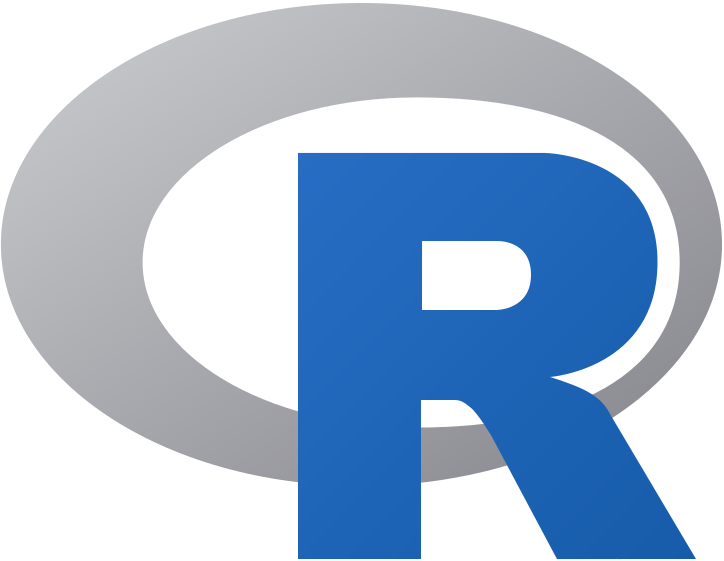

In [ ]:
la <- model_data |>
  group_by(LANAME) |>
  summarise(n_below   = sum(below_good),
            n_schools = n(),
            mean_fsm  = mean(PTFSM6CLA1A),
            mean_abs  = mean(PERCTOT),
            .groups   = "drop") |>
  filter(n_schools >= 5)

nrow(la)

[1] 150

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.000   1.000   3.000   3.167   4.000  22.000 

### B2 - Poisson regression, with an offset

An authority with 60 schools will have more schools below Good than one
with 8, for reasons that have nothing to do with poverty or absence. The
**offset** is how you tell the model to work in rates rather than raw
counts: it is a predictor whose coefficient is fixed at 1 rather than
estimated.

### 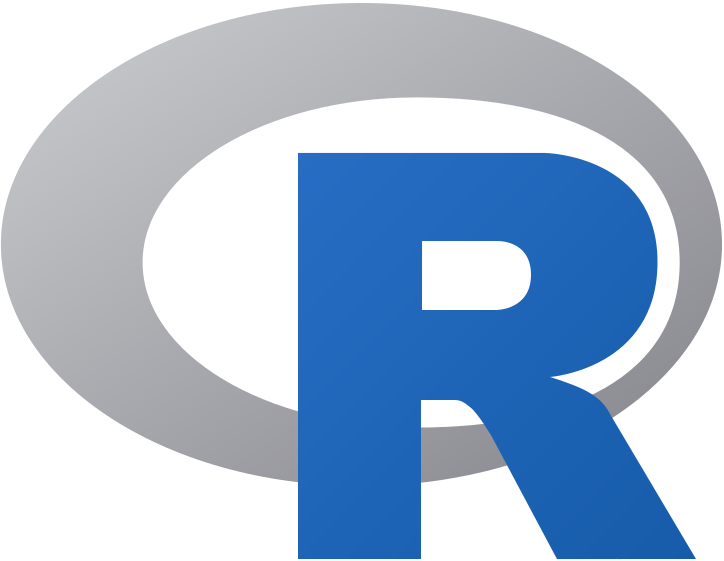

In [ ]:
pois <- glm(n_below ~ mean_fsm + mean_abs + offset(log(n_schools)),
            data = la, family = poisson)

summary(pois)


Call:
glm(formula = n_below ~ mean_fsm + mean_abs + offset(log(n_schools)), 
    family = poisson, data = la)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) -4.444128   0.442163 -10.051  < 2e-16 ***
mean_fsm    -0.002045   0.005498  -0.372     0.71    
mean_abs     0.279270   0.048094   5.807 6.37e-09 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 224.29  on 149  degrees of freedom
Residual deviance: 190.24  on 147  degrees of freedom
AIC: 573.49

Number of Fisher Scoring iterations: 5

> **Question**
>
> Fit it again **without** the offset and compare the coefficients.
> Which one changes most, and can you explain why in terms of what the
> offset was soaking up?

### B3 - Is it overdispersed?

The Poisson model assumes the variance equals the mean. That is a strong
assumption and it is usually wrong. Check it before you believe any of
the standard errors.

### 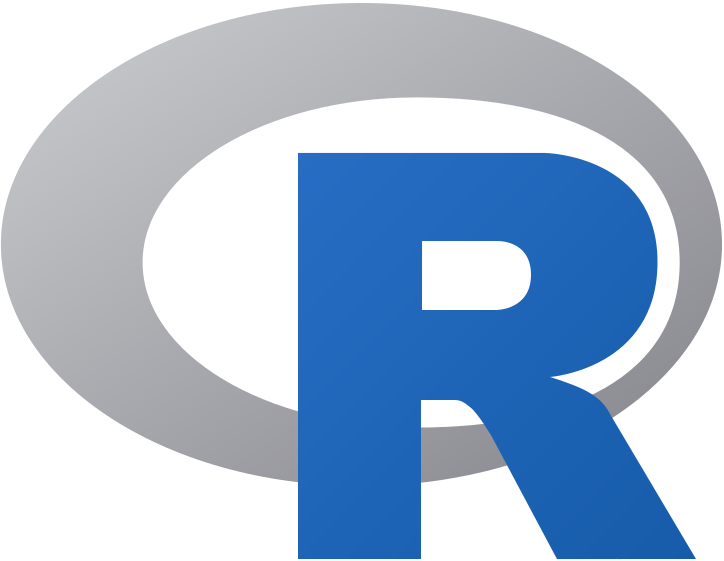

In [ ]:
sum(residuals(pois, type = "pearson")^2) / df.residual(pois)

[1] 1.247152

You should get **1.247**. A value of 1 is what Poisson assumes; much
above 2 and the Poisson standard errors are badly optimistic. 1.25 is
mild.

### B4 - Fit the negative binomial anyway, and decide whether it was needed

The negative binomial adds one parameter that lets the variance exceed
the mean. Fit it, and then make it earn its place.

### 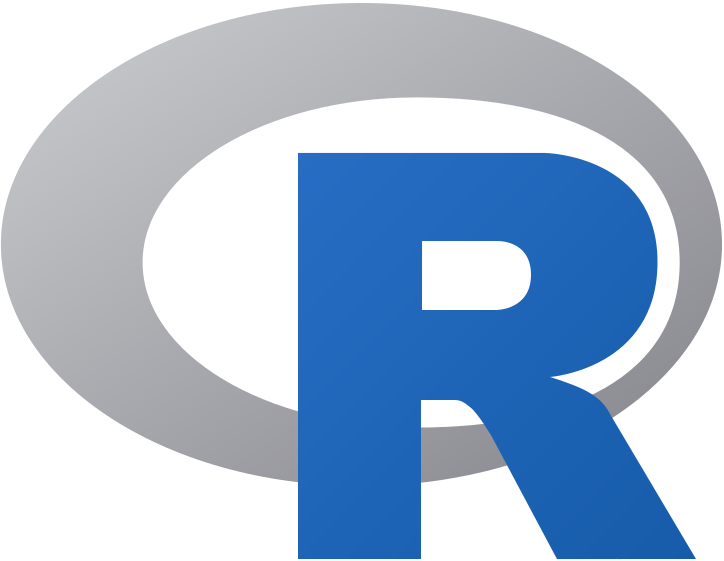

In [ ]:
nb <- MASS::glm.nb(n_below ~ mean_fsm + mean_abs + offset(log(n_schools)),
                   data = la)

c(poisson_AIC = round(AIC(pois), 1),
  nb_AIC      = round(AIC(nb), 1),
  theta       = round(nb$theta, 2))

poisson_AIC      nb_AIC       theta 
     573.50      572.40       19.72 

> **The result you were probably not expecting**
>
> Poisson AIC **573.5**, negative binomial AIC **572.4**. One AIC point,
> for a whole extra parameter.
>
> R reports `theta = 19.72` and Python reports `alpha = 0.0507`. They
> are the same number: alpha is 1/theta. A **large** theta -
> equivalently an alpha near zero - means the negative binomial has
> collapsed back towards the Poisson, because there was barely any extra
> dispersion for it to model.
>
> **The negative binomial was not needed here.** That is a perfectly
> good finding, and far more useful than reaching for the fancier model
> by reflex. Report the dispersion statistic, report that you checked,
> and keep the simpler model.

> **Question**
>
> Now go and find a count outcome in the DfE files that **is** badly
> overdispersed, and run the same four steps on it. Pupil destinations
> is a good hunting ground. What would you have got wrong if you had
> trusted the Poisson standard errors?

# Where this goes in your assessment

Three habits from today are worth carrying into the coursework, whatever
model you end up fitting:

1.  **Look at the outcome before choosing the model.** Binary, count,
    proportion, ordered category and continuous each have a family that
    fits them. Picking the family is a modelling decision you should
    justify in a sentence, not a default you fell into.
2.  **Never report accuracy without the baseline beside it.** Today’s
    model scored 86.9%, which sounds respectable until you notice that
    doing nothing also scores 86.9%.
3.  **Say what you are for.** If you are *explaining*, judge the model
    on the data you fitted it to and interpret the coefficients. If you
    are *predicting*, hold data back and judge it there. Both are
    legitimate. Deciding which one you are doing **before** you start
    changes what counts as a good model, and a write-up that quietly
    switches between them is the commonest way to overclaim.